# Chapitre 1 - Cours 2 : auto-supervision, échelle et modèles de fondation

Ce notebook couvre la suite de la section *The Rise of AI Engineering* : le volet
*Self-supervision* de *From Language Models to Large Language Models*, puis les
sous-sections *From Large Language Models to Foundation Models* et *From Foundation
Models to AI Engineering*. Le fil conducteur du livre tient en un mot : **l'échelle**.
Nous allons voir pourquoi l'auto-supervision l'a rendue possible, la mesurer (paramètres,
données, calcul) et suivre ses conséquences : des modèles multimodaux et généralistes,
qu'on adapte au lieu de les entraîner, d'où la naissance de l'AI engineering.

Plan :

1. supervision contre auto-supervision (et le coût de l'étiquetage) ;
2. comment un texte devient des paires d'entraînement (et la perte associée) ;
3. combien de paramètres ? (croissance, formule, mémoire) ;
4. pourquoi les gros modèles ont besoin de plus de données (règle de Chinchilla, FLOP) ;
5. des LLM aux modèles de fondation : la multimodalité (tokens d'image, apprentissage
   contrastif à la CLIP) ;
6. du modèle spécialisé au modèle généraliste ;
7. adapter un modèle : prompt, RAG, finetuning ;
8. des modèles de fondation à l'AI engineering.

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from aie.plotting import (INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch01_introduction as c1

c1.setup_style()
llm.seed_everything(0)
pd.set_option("display.max_colwidth", 100)

## 1. Supervision contre auto-supervision (section *Self-supervision*)

**Le problème.** Pourquoi les modèles de langage, plutôt que les modèles de détection
d'objets ou de recommandation, ont-ils été au cœur de la course à l'échelle ? Parce que
leur apprentissage ne demande **aucune étiquette humaine**.

- En **apprentissage supervisé**, chaque exemple $x$ doit être accompagné d'une étiquette
  $y$ fournie par un humain (« fraude » / « pas fraude », « chat » / « chien »). C'est le
  paradigme des années 2010 (AlexNet sur ImageNet).
- En **auto-supervision**, les étiquettes sont **déduites des données elles-mêmes** : dans
  un texte, chaque token sert de cible pour le contexte qui le précède.
- En **non-supervisé** (clustering, par exemple), il n'y a pas d'étiquette du tout.

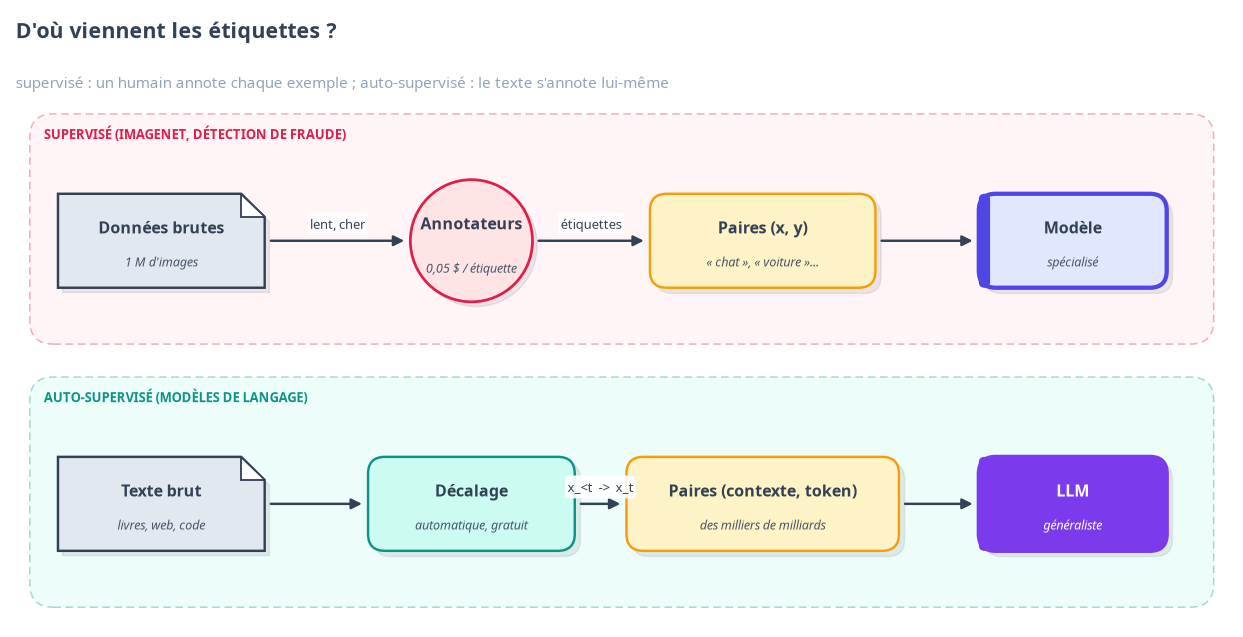

In [2]:
d = Diagram(13, 5.6, title="D'où viennent les étiquettes ?",
            subtitle="supervisé : un humain annote chaque exemple ; auto-supervisé : le texte s'annote lui-même")
d.group(0.2, 3.0, 12.8, 5.45, "Supervisé (ImageNet, détection de fraude)", ROSE)
d.box("img", 1.6, 4.1, "Données brutes", sub="1 M d'images", color=SLATE, kind="doc", w=2.2, h=1.0)
d.box("hum", 4.9, 4.1, "Annotateurs", sub="0,05 $ / étiquette", color=ROSE, kind="user", w=1.3)
d.box("lab", 8.0, 4.1, "Paires (x, y)", sub="« chat », « voiture »...", color=AMBER, w=2.4, h=1.0)
d.box("m1", 11.3, 4.1, "Modèle", sub="spécialisé", color=INDIGO, kind="model", w=2.0, h=1.0)
d.arrow("img", "hum", "lent, cher")
d.arrow("hum", "lab", "étiquettes")
d.arrow("lab", "m1")
d.group(0.2, 0.2, 12.8, 2.65, "Auto-supervisé (modèles de langage)", TEAL)
d.box("txt", 1.6, 1.3, "Texte brut", sub="livres, web, code", color=SLATE, kind="doc", w=2.2, h=1.0)
d.box("auto", 4.9, 1.3, "Décalage", sub="automatique, gratuit", color=TEAL, w=2.2, h=1.0)
d.box("pairs", 8.0, 1.3, "Paires (contexte, token)", sub="des milliers de milliards", color=AMBER, w=2.9, h=1.0)
d.box("m2", 11.3, 1.3, "LLM", sub="généraliste", color=VIOLET, kind="model", w=2.0, h=1.0, filled=True)
d.arrow("txt", "auto")
d.arrow("auto", "pairs", "x_<t  ->  x_t")
d.arrow("pairs", "m2")
d.show()

**Ordres de grandeur.** Reprenons le calcul du livre : à 5 centimes l'étiquette, annoter
le million d'images d'ImageNet coûte 50 000 $, le double avec deux annotateurs par image
(pour contrôler la qualité). Passer de 1 000 à un million de catégories multiplie le coût
par mille. Comparons avec ce qu'aurait coûté l'« étiquetage » du corpus de pré-entraînement
d'un LLM moderne (15 000 milliards de tokens pour Llama 3) si chaque cible devait être
fournie par un humain, même à un dixième de centime.

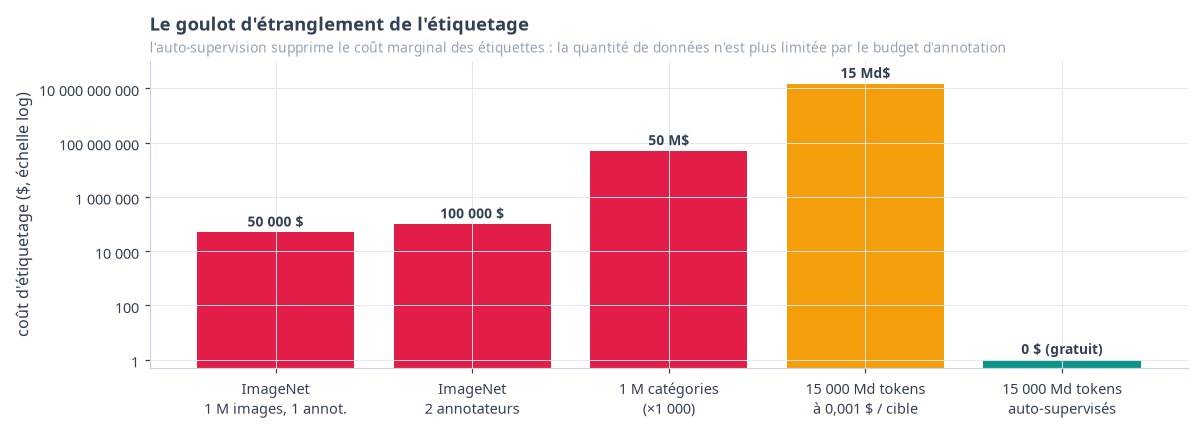

In [3]:
scen = {
    "ImageNet\n1 M images, 1 annot.": c1.labeling_cost(1e6, 0.05),
    "ImageNet\n2 annotateurs": c1.labeling_cost(1e6, 0.05, 2),
    "1 M catégories\n(×1 000)": c1.labeling_cost(1e9, 0.05),
    "15 000 Md tokens\nà 0,001 $ / cible": c1.labeling_cost(15e12, 0.001),
    "15 000 Md tokens\nauto-supervisés": 0.0,
}
fig, ax = plt.subplots(figsize=(11, 4))
vals = np.array(list(scen.values()))
ax.bar(list(scen), np.maximum(vals, 1), color=[ROSE, ROSE, ROSE, AMBER, TEAL])
ax.set_yscale("log"); c1.plain_log(ax)
for i, v in enumerate(vals):
    lab = ("0 $ (gratuit)" if v == 0 else f"{v / 1e9:,.0f} Md$" if v >= 1e9 else
           f"{v / 1e6:,.0f} M$" if v >= 1e6 else f"{v:,.0f} $")
    ax.text(i, max(v, 1) * 1.6, lab.replace(",", " "), ha="center", fontsize=9, fontweight="bold")
ax.set_ylabel("coût d'étiquetage ($, échelle log)")
ax.set_ylim(0.5, 1e11)
c1.title_sub(ax, "Le goulot d'étranglement de l'étiquetage",
             "l'auto-supervision supprime le coût marginal des étiquettes : la quantité de données n'est plus limitée par le budget d'annotation")
plt.tight_layout(); plt.show()

> **À retenir.** L'auto-supervision fait disparaître le coût d'étiquetage : chaque texte
> fournit à la fois les entrées et les cibles. C'est ce qui a permis d'entraîner les
> modèles de langage sur des quantités de données sans commune mesure avec ImageNet.

## 2. Comment un texte devient des paires d'entraînement (section *Self-supervision*)

Le livre illustre l'idée avec une phrase de cinq tokens qui donne six exemples
d'entraînement. Le principe : on encadre la séquence par deux tokens spéciaux, `<BOS>`
(début) et `<EOS>` (fin), puis chaque position fournit une paire (tout ce qui précède,
token courant). Le token `<EOS>` est crucial : c'est en apprenant à le prédire que le
modèle apprend **à s'arrêter**. Faisons-le avec la fonction `autoregressive_pairs` du
module, sur une phrase française découpée en mots.

In [4]:
phrase = ["J'", "adore", "la", "cuisine", "de", "rue", "."]
c1.pairs_table(c1.autoregressive_pairs(phrase))

,entrée (contexte),sortie (prochain token)
0,<BOS>,J'
1,<BOS> J',adore
2,<BOS> J' adore,la
3,<BOS> J' adore la,cuisine
4,<BOS> J' adore la cuisine,de
5,<BOS> J' adore la cuisine de,rue
6,<BOS> J' adore la cuisine de rue,.
7,<BOS> J' adore la cuisine de rue .,<EOS>


Une phrase de $n$ tokens donne donc $n + 1$ paires (avec `<EOS>`). En pratique, on
travaille avec les vrais tokens du modèle, et les paires sont implicites : on donne au
réseau la séquence entière **en une seule passe**, et il produit une prédiction à chaque
position. Les cibles sont la même séquence **décalée d'un cran** ; le masque causal (cours
1) garantit qu'aucune position ne « triche » en regardant sa cible. C'est le *teacher
forcing*.

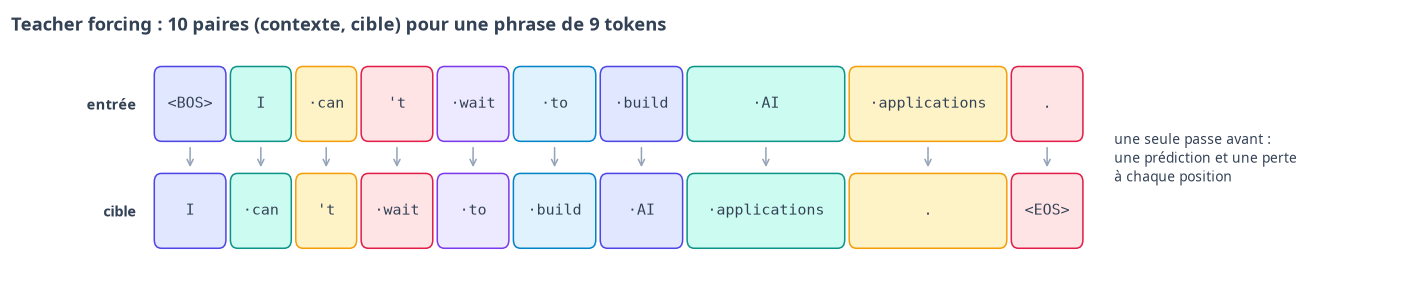

In [5]:
tok_g = c1.get_tokenizer("GPT-2")
sent = "I can't wait to build AI applications."
pieces = tok_g.pieces(sent)
inp = ["<BOS>"] + pieces
tgt = pieces + ["<EOS>"]
fig, ax = plt.subplots(figsize=(13, 2.7))
col_w = [max(0.45, 0.12 * max(len(a), len(b)) + 0.2) for a, b in zip(inp, tgt)]
x_end = c1.draw_tokens(ax, inp, y=1.0, x0=1.6, label="entrée", fontsize=9.5, widths=col_w)
c1.draw_tokens(ax, tgt, y=0.0, x0=1.6, label="cible", fontsize=9.5, widths=col_w)
xc = 1.6
for w in col_w:  # la position t de l'entrée prédit la position t de la cible
    ax.annotate("", xy=(xc + w / 2, 0.38), xytext=(xc + w / 2, 0.62), arrowprops=dict(arrowstyle="->", color=GRAY))
    xc += w + 0.05
ax.text(x_end + 0.3, 0.5, "une seule passe avant :\nune prédiction et une perte\nà chaque position",
        fontsize=9, va="center", color=SLATE)
ax.set_xlim(0, 15.6); ax.set_ylim(-0.6, 1.6); ax.axis("off")
ax.set_title(f"Teacher forcing : {len(tgt)} paires (contexte, cible) pour une phrase de {len(pieces)} tokens", loc="left")
plt.tight_layout(); plt.show()

**La perte associée.** Pour chaque paire, le modèle est pénalisé par la **surprise**
$-\log p_\theta(x_t \mid x_{<t})$ qu'il attribue au vrai token. La perte d'entraînement est
la moyenne de ces surprises, l'**entropie croisée** :
$$\mathcal L(\theta) = -\frac{1}{T} \sum_{t=1}^{T} \log p_\theta(x_t \mid x_{<t}),
  \qquad \text{perplexité} = e^{\mathcal L}.$$
La perplexité s'interprète comme le nombre de tokens entre lesquels le modèle hésite « en
moyenne » (chapitre 3). Mesurons la surprise de GPT-2 sur chaque paire de notre phrase.

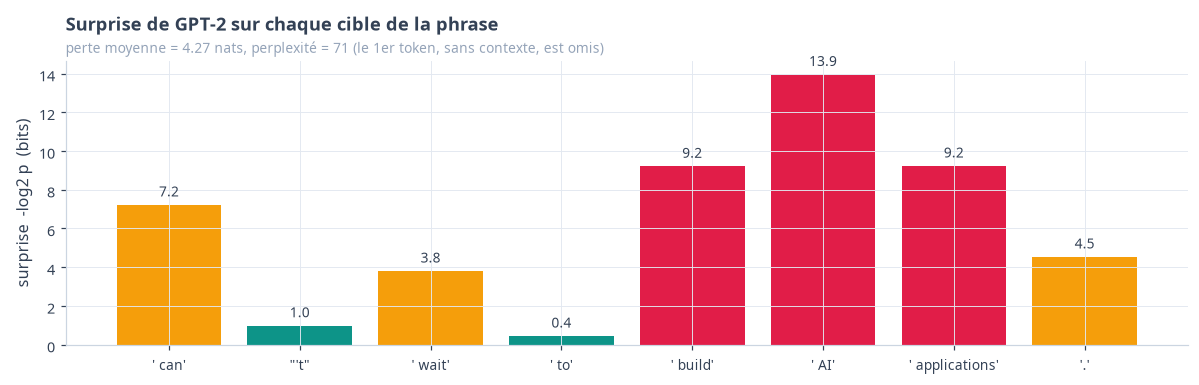

In [6]:
toks, lp = llm.token_logprobs(sent, llm.BASE)
surprise_bits = -lp / np.log(2)
fig, ax = plt.subplots(figsize=(11, 3.6))
cols = [ROSE if s > 8 else (AMBER if s > 3 else TEAL) for s in surprise_bits]
ax.bar(range(len(toks)), surprise_bits, color=cols)
ax.set_xticks(range(len(toks)), [repr(t) for t in toks], rotation=0, fontsize=9)
ax.set_ylabel("surprise  -log2 p  (bits)")
annotate_bars(ax, "{:.1f}")
c1.title_sub(ax, "Surprise de GPT-2 sur chaque cible de la phrase",
             f"perte moyenne = {-lp.mean():.2f} nats, perplexité = {np.exp(-lp.mean()):.0f} "
             "(le 1er token, sans contexte, est omis)")
plt.tight_layout(); plt.show()

« 't » après « can » et « to » après « can't wait » sont quasi certains (moins d'un bit de
surprise) : GPT-2 a vu ces suites des millions de fois. « build », « AI » et
« applications » le surprennent bien davantage (le sujet de la phrase est imprévisible) : ce sont précisément ces cas que l'entraînement améliore, en ajustant les
paramètres $\theta$ par descente de gradient sur $\mathcal L$.

**Combien de paires ?** Un corpus de $N$ tokens fournit environ $N$ paires (une par
position). Avec une fenêtre de contexte de longueur $C$, on découpe le corpus en
$\lceil N / C \rceil$ séquences, chacune traitée en une passe.

In [7]:
for N, name in [(5e9, "Wikipédia anglophone (~5 Md tokens)"), (300e9, "GPT-3 (300 Md tokens)"),
                (15e12, "Llama 3 (15 000 Md tokens)")]:
    print(f"{name:38s} -> {N:9.1e} paires ; {N / 8192:9.2e} séquences de 8 192 tokens")

Wikipédia anglophone (~5 Md tokens)    ->   5.0e+09 paires ;  6.10e+05 séquences de 8 192 tokens
GPT-3 (300 Md tokens)                  ->   3.0e+11 paires ;  3.66e+07 séquences de 8 192 tokens
Llama 3 (15 000 Md tokens)             ->   1.5e+13 paires ;  1.83e+09 séquences de 8 192 tokens


> **À retenir.** Une séquence de $n$ tokens donne $n$ (ou $n+1$) exemples d'entraînement
> gratuits ; une passe avant les traite tous à la fois grâce au masque causal. La perte
> est la surprise moyenne (entropie croisée) ; son exponentielle est la perplexité.

## 3. Combien de paramètres ? (section *Self-supervision*, sur les LLM)

Le livre souligne que « large » n'a rien de scientifique : GPT-1 (117 M de paramètres,
2018) était « grand » jusqu'à l'arrivée de GPT-2 (1,5 Md, 2019) ; au moment de la
rédaction, « grand » signifie plutôt 100 Md. Un **paramètre** est une variable du modèle
ajustée pendant l'entraînement (on dit aussi « poids »). Visualisons la croissance avec
les tailles publiées de quelques modèles marquants.

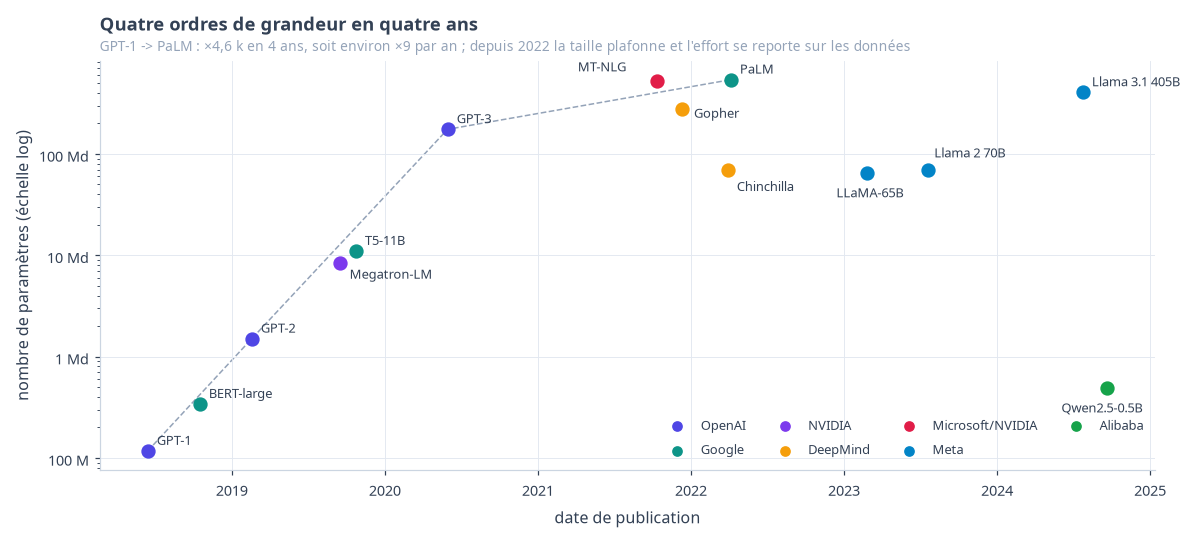

In [8]:
ms = c1.model_sizes_frame()
fig, ax = plt.subplots(figsize=(11, 5))
orgs = ms["organisation"].unique()
cmap = dict(zip(orgs, [INDIGO, TEAL, VIOLET, AMBER, ROSE, SKY, GREEN, SLATE]))
for _, r in ms.iterrows():
    ax.scatter(r["date"], r["params_Md"] * 1e9, s=70, color=cmap[r["organisation"]], zorder=5)
    off = {"Chinchilla": (6, -14), "Megatron-LM": (6, -10), "MT-NLG": (-52, 6), "PaLM": (6, 4),
           "Gopher": (8, -6), "Qwen2.5-0.5B": (-30, -16), "LLaMA-65B": (-20, -16),
           "Llama 2 70B": (4, 8)}.get(r["modèle"], (6, 4))
    ax.annotate(r["modèle"], (r["date"], r["params_Md"] * 1e9), textcoords="offset points",
                xytext=off, fontsize=8.5)
big = ms[ms["modèle"].isin(["GPT-1", "GPT-2", "GPT-3", "PaLM"])]
slope = np.polyfit(big["date"], np.log10(big["params_Md"] * 1e9), 1)[0]
ax.plot(big["date"], big["params_Md"] * 1e9, color=GRAY, ls="--", lw=1, zorder=1)
ax.set_yscale("log"); c1.human_log(ax)
ax.set_ylabel("nombre de paramètres (échelle log)")
ax.set_xlabel("date de publication")
for o, ccol in cmap.items():
    ax.scatter([], [], color=ccol, label=o)
ax.legend(ncol=4, loc="lower right", fontsize=8.5)
c1.title_sub(ax, "Quatre ordres de grandeur en quatre ans",
             f"GPT-1 -> PaLM : ×{c1.human_number(540 / 0.117)} en 4 ans, soit environ ×{10 ** slope:.0f} par an ; "
             "depuis 2022 la taille plafonne et l'effort se reporte sur les données")
plt.tight_layout(); plt.show()

**D'où viennent ces nombres ?** Pour un transformer décodeur de $L$ couches et de
dimension $d$, chaque couche contient l'attention (4 matrices $d \times d$ : requêtes,
clés, valeurs, sortie) et un MLP (deux matrices $d \times 4d$), soit environ
$4d^2 + 8d^2 = 12 d^2$ paramètres. En ajoutant la table d'embeddings $V \times d$ :
$$N \approx 12\,L\,d^2 + V d.$$
Pour GPT-3 ($L = 96$, $d = 12\,288$) : $12 \times 96 \times 12\,288^2 \approx 174$ Md, plus
0,6 Md d'embeddings : on retrouve les 175 Md annoncés. Vérifions la formule (et sa
variante moderne) contre le décompte exact de deux modèles locaux, chargés sur CPU.

In [9]:
from transformers import AutoConfig, AutoModelForCausalLM

rows = []
for mid in [llm.BASE, llm.SMALL]:
    cfg = AutoConfig.from_pretrained(mid)
    model_cpu = AutoModelForCausalLM.from_pretrained(mid, dtype="auto", device_map="cpu")
    exact = llm.count_params(model_cpu)
    del model_cpu
    if mid == llm.BASE:
        est = c1.transformer_params(cfg.n_layer, cfg.n_embd, cfg.vocab_size, n_ctx=cfg.n_positions)
        arch = f"L={cfg.n_layer}, d={cfg.n_embd}, V={cfg.vocab_size}"
    else:  # Qwen2.5 : MLP « gated » (SwiGLU), attention à requêtes groupées (GQA)
        kv = cfg.num_key_value_heads / cfg.num_attention_heads
        est = c1.transformer_params(cfg.num_hidden_layers, cfg.hidden_size, cfg.vocab_size,
                                    d_ff=cfg.intermediate_size, gated=True, kv_ratio=kv,
                                    tied=cfg.tie_word_embeddings)
        arch = (f"L={cfg.num_hidden_layers}, d={cfg.hidden_size}, d_ff={cfg.intermediate_size}, "
                f"V={cfg.vocab_size}, GQA {cfg.num_key_value_heads}/{cfg.num_attention_heads}")
    rows.append({"modèle": mid, "architecture": arch, "estimation": f"{est / 1e6:.1f} M",
                 "décompte exact": f"{exact / 1e6:.1f} M", "écart": f"{(est - exact) / exact:+.1%}",
                 "part des embeddings": f"{cfg.vocab_size * (cfg.n_embd if mid == llm.BASE else cfg.hidden_size) / exact:.0%}"})
pd.DataFrame(rows)

,modèle,architecture,estimation,décompte exact,écart,part des embeddings
0,gpt2,"L=12, d=768, V=50257",124.3 M,124.4 M,-0.1%,31%
1,Qwen/Qwen2.5-0.5B-Instruct,"L=24, d=896, d_ff=4864, V=151936, GQA 2/14",494.0 M,494.0 M,-0.0%,28%


La formule tombe à moins de 1 % près (l'écart restant vient des biais et normalisations,
négligés). Détail instructif : pour ces **petits** modèles, la table d'embeddings pèse
lourd (un tiers des paramètres de GPT-2, plus d'un quart de Qwen2.5-0.5B avec son
vocabulaire de 151 k tokens), alors qu'elle est négligeable pour GPT-3. La taille du
vocabulaire est donc un vrai choix d'architecture (chapitre 2).

**Ce que cela coûte en mémoire.** Stocker les poids en bf16 demande 2 octets par
paramètre (le chapitre 7 montre comment la quantification réduit ce chiffre).

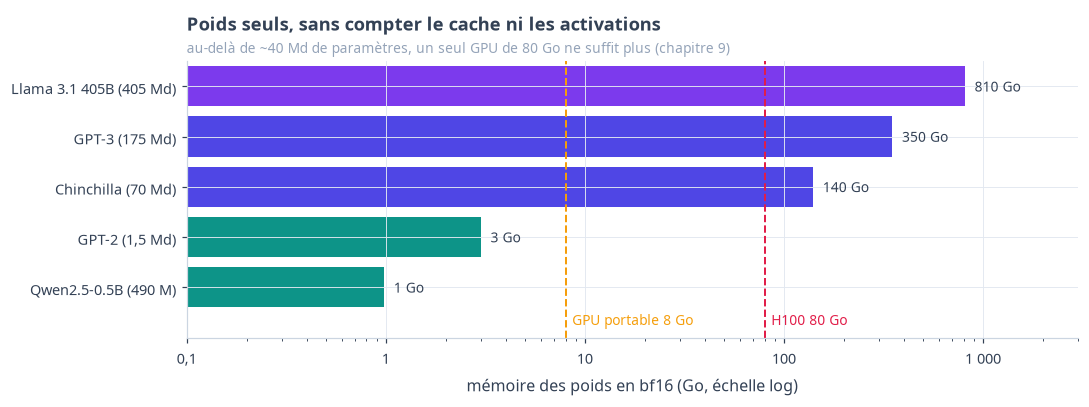

In [10]:
sel = ["Qwen2.5-0.5B", "GPT-2", "Chinchilla", "GPT-3", "Llama 3.1 405B"]
mem = {f"{m} ({c1.human_number(ms.loc[ms['modèle'] == m, 'params_Md'].item() * 1e9)})":
       c1.weights_memory_gb(ms.loc[ms["modèle"] == m, "params_Md"].item() * 1e9) for m in sel}
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(list(mem), list(mem.values()), color=[TEAL, TEAL, INDIGO, INDIGO, VIOLET])
ax.set_xscale("log"); c1.plain_log(ax, "x")
for gpu, gb, col in [("GPU portable 8 Go", 8, AMBER), ("H100 80 Go", 80, ROSE)]:
    ax.axvline(gb, color=col, ls="--", lw=1.3)
    ax.text(gb * 1.08, -0.75, gpu, color=col, fontsize=9)
for i, v in enumerate(mem.values()):
    ax.text(v * 1.12, i, f"{v:,.0f} Go".replace(",", " "), va="center", fontsize=9)
ax.set_ylim(-1, len(mem) - 0.5)
ax.set_xlabel("mémoire des poids en bf16 (Go, échelle log)")
c1.title_sub(ax, "Poids seuls, sans compter le cache ni les activations",
             "au-delà de ~40 Md de paramètres, un seul GPU de 80 Go ne suffit plus (chapitre 9)")
ax.set_xlim(0.1, 3000)
plt.tight_layout(); plt.show()

> **À retenir.** La taille d'un modèle se mesure en paramètres, $N \approx 12 L d^2 + V d$
> pour un transformer classique. Le seuil du « grand » se déplace sans cesse ; la mémoire
> nécessaire ($2N$ octets en bf16) est la première contrainte d'ingénierie.